In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten, InputLayer
import cv2
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import pydicom

In [51]:
train_data = pd.read_csv('../data/train.csv')
test_data = pd.read_csv('../data/sample_submission.csv')

TRAIN_PATH = '../data/images/train/'

In [52]:

print(train_data['Target'][7])
train_data['Target1'] = train_data['Target'].apply(lambda x: x.strip(' '))
print(train_data['Target1'][7])

13 20 
13 20


In [53]:
train_data['Target'] = train_data['Target'].apply(lambda x: x.strip(' '))
#train_data['Target'] = train_data['Target'].apply(lambda x: x.split(' ')[0])
print(train_data['Target'][7])

13 20


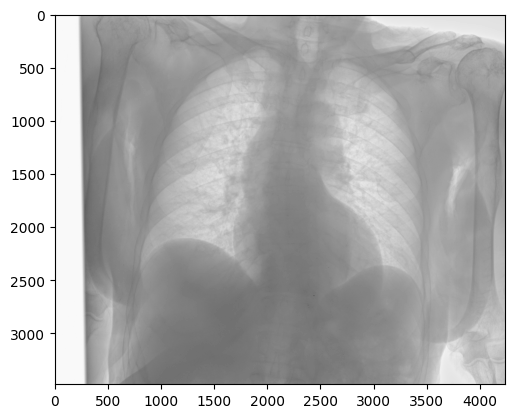

In [54]:
val = train_data.loc[7].SOPInstanceUID
val = val + '-c.png'
img = plt.imread(TRAIN_PATH + val)
plt.imshow(img,cmap='gray')

In [55]:
multi = []
multi_target = []
for i,val in enumerate(train_data.Target):
        if len(val) > 2: 
            multi.append(train_data.iloc[i].SOPInstanceUID)
            multi_target.append(train_data.iloc[i].Target)


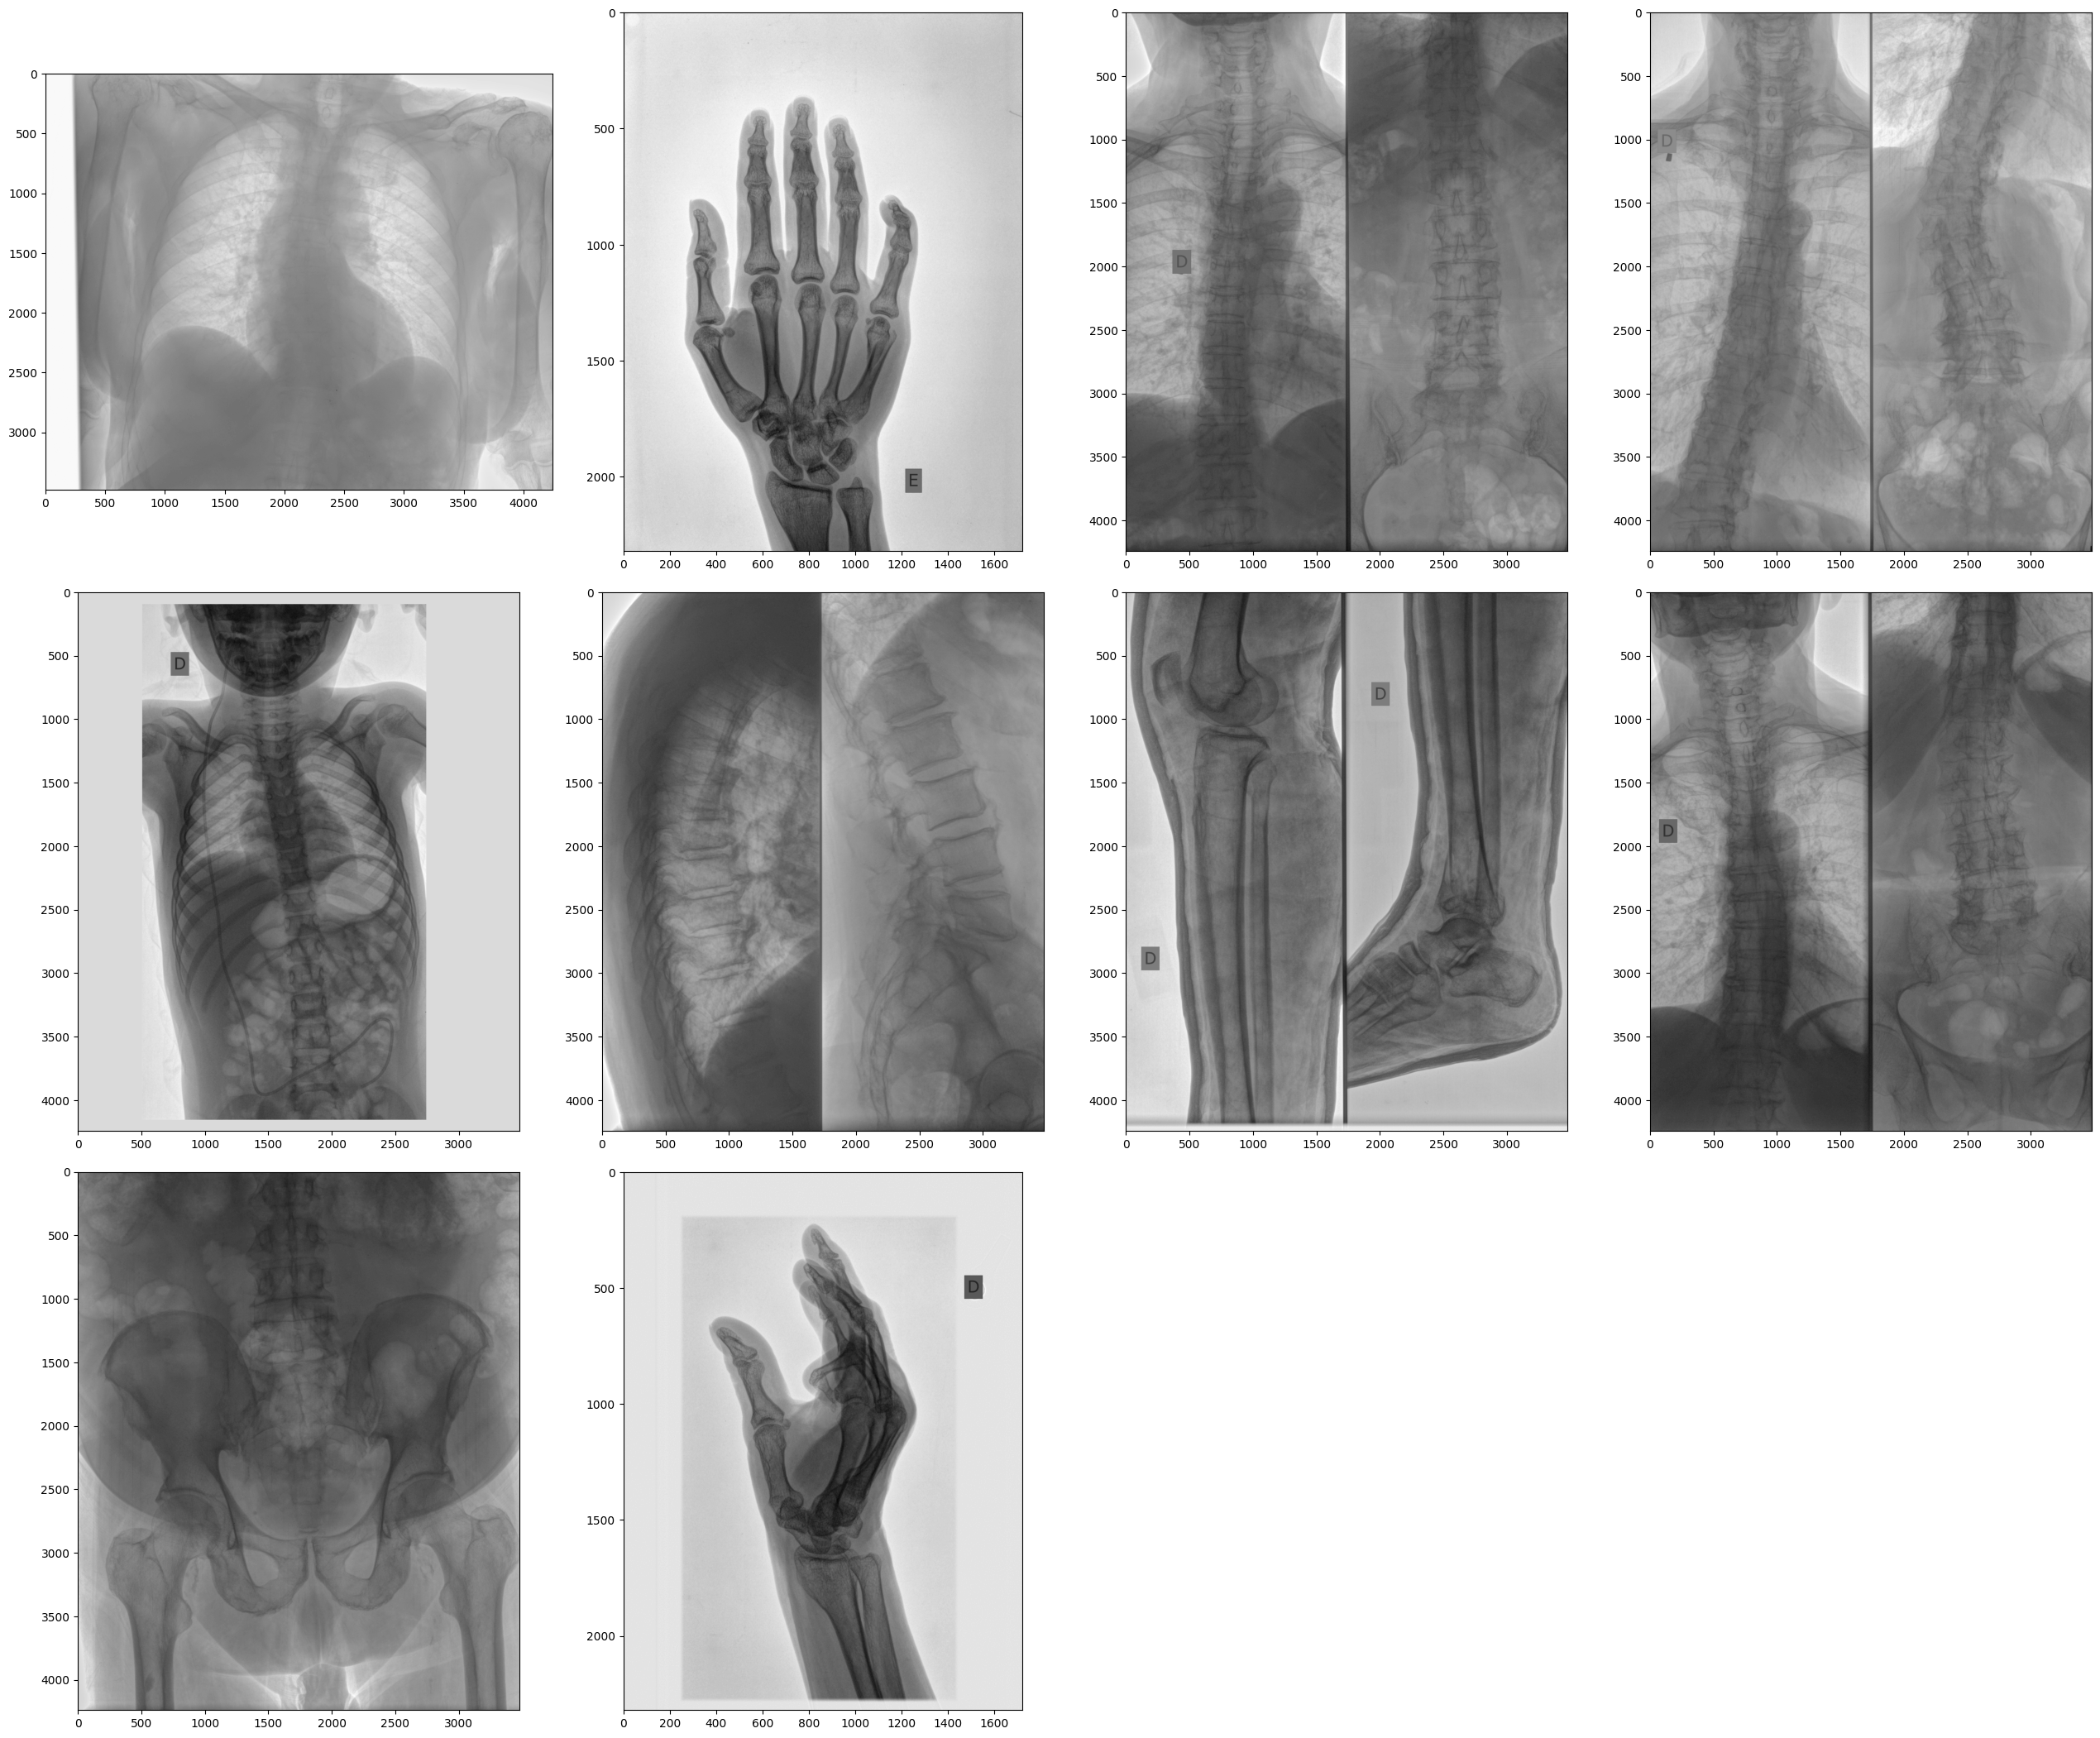

In [56]:
plt.figure(figsize=(26,28))
for i in range(10):
    plt.subplot(4,4,i+1)
    val = multi[i] + '-c.png'
    img = plt.imread(TRAIN_PATH + val)
    plt.imshow(img,cmap='gray')
    
plt.tight_layout(pad=1.5)

In [57]:
train_dff = pd.DataFrame()
train_dff['SOPInstanceUID'] = train_data['SOPInstanceUID'].copy()
train_dff['Target'] = train_data['Target'].copy()
train_dff.head(2)


,SOPInstanceUID,Target
0,1.2.826.0.1.3680043.8.498.10025629581362719970...,0
1,1.2.826.0.1.3680043.8.498.10036150326276641158...,15


In [58]:
def Names(label):
    if label == '0':
        return 'Abdomen'
    elif label == '1':
        return 'Ankle'
    elif label == '2':
        return 'Cervical Spine'
    elif label == '3':
        return 'Chest'
    elif label == '4':
        return 'Clavicles'
    elif label == '5':
        return 'Elbow'
    elif label == '6':
        return 'Feet'
    elif label == '7':
        return 'Finger'
    elif label == '8':
        return 'Forearm'
    elif label == '9':
        return 'Hand'
    elif label == '10':
        return 'Hip'
    elif label == '11':
        return 'Knee'
    elif label == '12':
        return 'Lower Leg'
    elif label == '13':
        return 'Lumbar Spine'
    elif label == '14':
        return 'Others'
    elif label == '15':
        return 'Pelvis'
    elif label == '16':
        return 'Shoulder'
    elif label == '17':
        return 'Sinus'
    elif label == '18':
        return 'Skull'
    elif label == '19':
        return 'Thigh'
    elif label == '20':
        return 'Thoracic Spine'
    elif label == '21':
        return 'Wrist'

In [59]:
x,x1 = train_dff.iloc[7]['Target'].split(' ',1)
x_name = Names(x)
x1_name = Names(x1)
print(x_name + ' '+ x1_name) 

Lumbar Spine Thoracic Spine


In [60]:
for i,val in enumerate(train_dff.Target):
    if len(val) > 2 and len(val) <=6:
        
        x,x1 = train_dff.iloc[i]['Target'].split(' ',1)
        x_name = Names(x)
        x1_name = Names(x1)
        total = x_name + ' ' + x1_name
        train_dff.at[i, 'label'] = total
    elif len(val) >=7:
        
        x,x1,x2 = train_dff.iloc[i]['Target'].split(' ',2)
        x_name = Names(x)
        x1_name = Names(x1)
        x2_name = Names(x2)
        total = x_name+' '+x1_name+' '+x2_name
        train_dff.at[i, 'label']  = total
    else:
        x = train_dff.iloc[i]['Target']
        x_name = Names(x)
        train_dff.at[i, 'label']  = x_name

In [61]:
train_dff = pd.get_dummies(train_dff['label'])
train_dff['SOPInstanceUID'] = train_data['SOPInstanceUID']
train_dff['Target'] = train_data['Target']
train_dff.head(3)

,Abdomen,Abdomen Chest,Abdomen Pelvis,Ankle,Ankle Feet,Ankle Knee Lower Leg,Ankle Lower Leg,Cervical Spine,Cervical Spine Lumbar Spine Thoracic Spine,Cervical Spine Thoracic Spine,...,Pelvis,Pelvis Thigh,Shoulder,Sinus,Skull,Thigh,Thoracic Spine,Wrist,SOPInstanceUID,Target
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,1.2.826.0.1.3680043.8.498.10025629581362719970...,0
1,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,1.2.826.0.1.3680043.8.498.10036150326276641158...,15
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,1.2.826.0.1.3680043.8.498.10038426859954986240...,12


In [62]:
new_train_data = pd.merge(train_data,train_dff,on='SOPInstanceUID')

In [63]:
new_train_data.head(20)

,SOPInstanceUID,Target_x,Target1,Abdomen,Abdomen Chest,Abdomen Pelvis,Ankle,Ankle Feet,Ankle Knee Lower Leg,Ankle Lower Leg,...,Others,Pelvis,Pelvis Thigh,Shoulder,Sinus,Skull,Thigh,Thoracic Spine,Wrist,Target_y
0,1.2.826.0.1.3680043.8.498.10025629581362719970...,0,0,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,0
1,1.2.826.0.1.3680043.8.498.10036150326276641158...,15,15,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,15
2,1.2.826.0.1.3680043.8.498.10038426859954986240...,12,12,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,12
3,1.2.826.0.1.3680043.8.498.10050991192143676483...,14,14,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,14
4,1.2.826.0.1.3680043.8.498.10053309524595490852...,3,3,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,3
5,1.2.826.0.1.3680043.8.498.10053755320637729867...,3,3,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,3
6,1.2.826.0.1.3680043.8.498.10062189329714053601...,14,14,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,14
7,1.2.826.0.1.3680043.8.498.10065930002825553435...,13 20,13 20,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,13 20
8,1.2.826.0.1.3680043.8.498.10072001800484199846...,3,3,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,3
9,1.2.826.0.1.3680043.8.498.10077219503857952412...,3,3,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,3


In [64]:
new_train_data.drop('Target_y',axis=1,inplace=True)

In [65]:
new_train_data.columns[3:]

Index(['Abdomen', 'Abdomen Chest', 'Abdomen Pelvis', 'Ankle', 'Ankle Feet',
       'Ankle Knee Lower Leg', 'Ankle Lower Leg', 'Cervical Spine',
       'Cervical Spine Lumbar Spine Thoracic Spine',
       'Cervical Spine Thoracic Spine', 'Chest', 'Chest Feet', 'Chest Finger',
       'Chest Pelvis', 'Clavicles', 'Elbow', 'Elbow Forearm', 'Feet', 'Finger',
       'Finger Hand', 'Forearm', 'Forearm Shoulder', 'Hand', 'Hand Wrist',
       'Hip', 'Hip Knee Thigh', 'Hip Thigh', 'Knee', 'Knee Lower Leg',
       'Lower Leg', 'Lumbar Spine', 'Lumbar Spine Thoracic Spine', 'Others',
       'Pelvis', 'Pelvis Thigh', 'Shoulder', 'Sinus', 'Skull', 'Thigh',
       'Thoracic Spine', 'Wrist'],
      dtype='object')

In [66]:
TRAIN_PATH = '../data/images/train/'
X = []
y = []

In [67]:
for val in new_train_data.SOPInstanceUID:
    idd = val
    val = val + '-c.png'
    img = plt.imread(TRAIN_PATH + val) 
    img = cv2.resize(img,dsize=(128,128))
    img_norm = cv2.normalize(img,None,alpha=0,beta=500,norm_type=cv2.NORM_MINMAX)
    y.append(np.ndarray.flatten(np.array(new_train_data.loc[new_train_data['SOPInstanceUID'] == idd][new_train_data.columns[3:]])))
    X.append(np.expand_dims(img,axis=-1))

X = np.array(X)
y = np.array(y)

In [68]:
np.argmax(y[0])

np.int64(0)

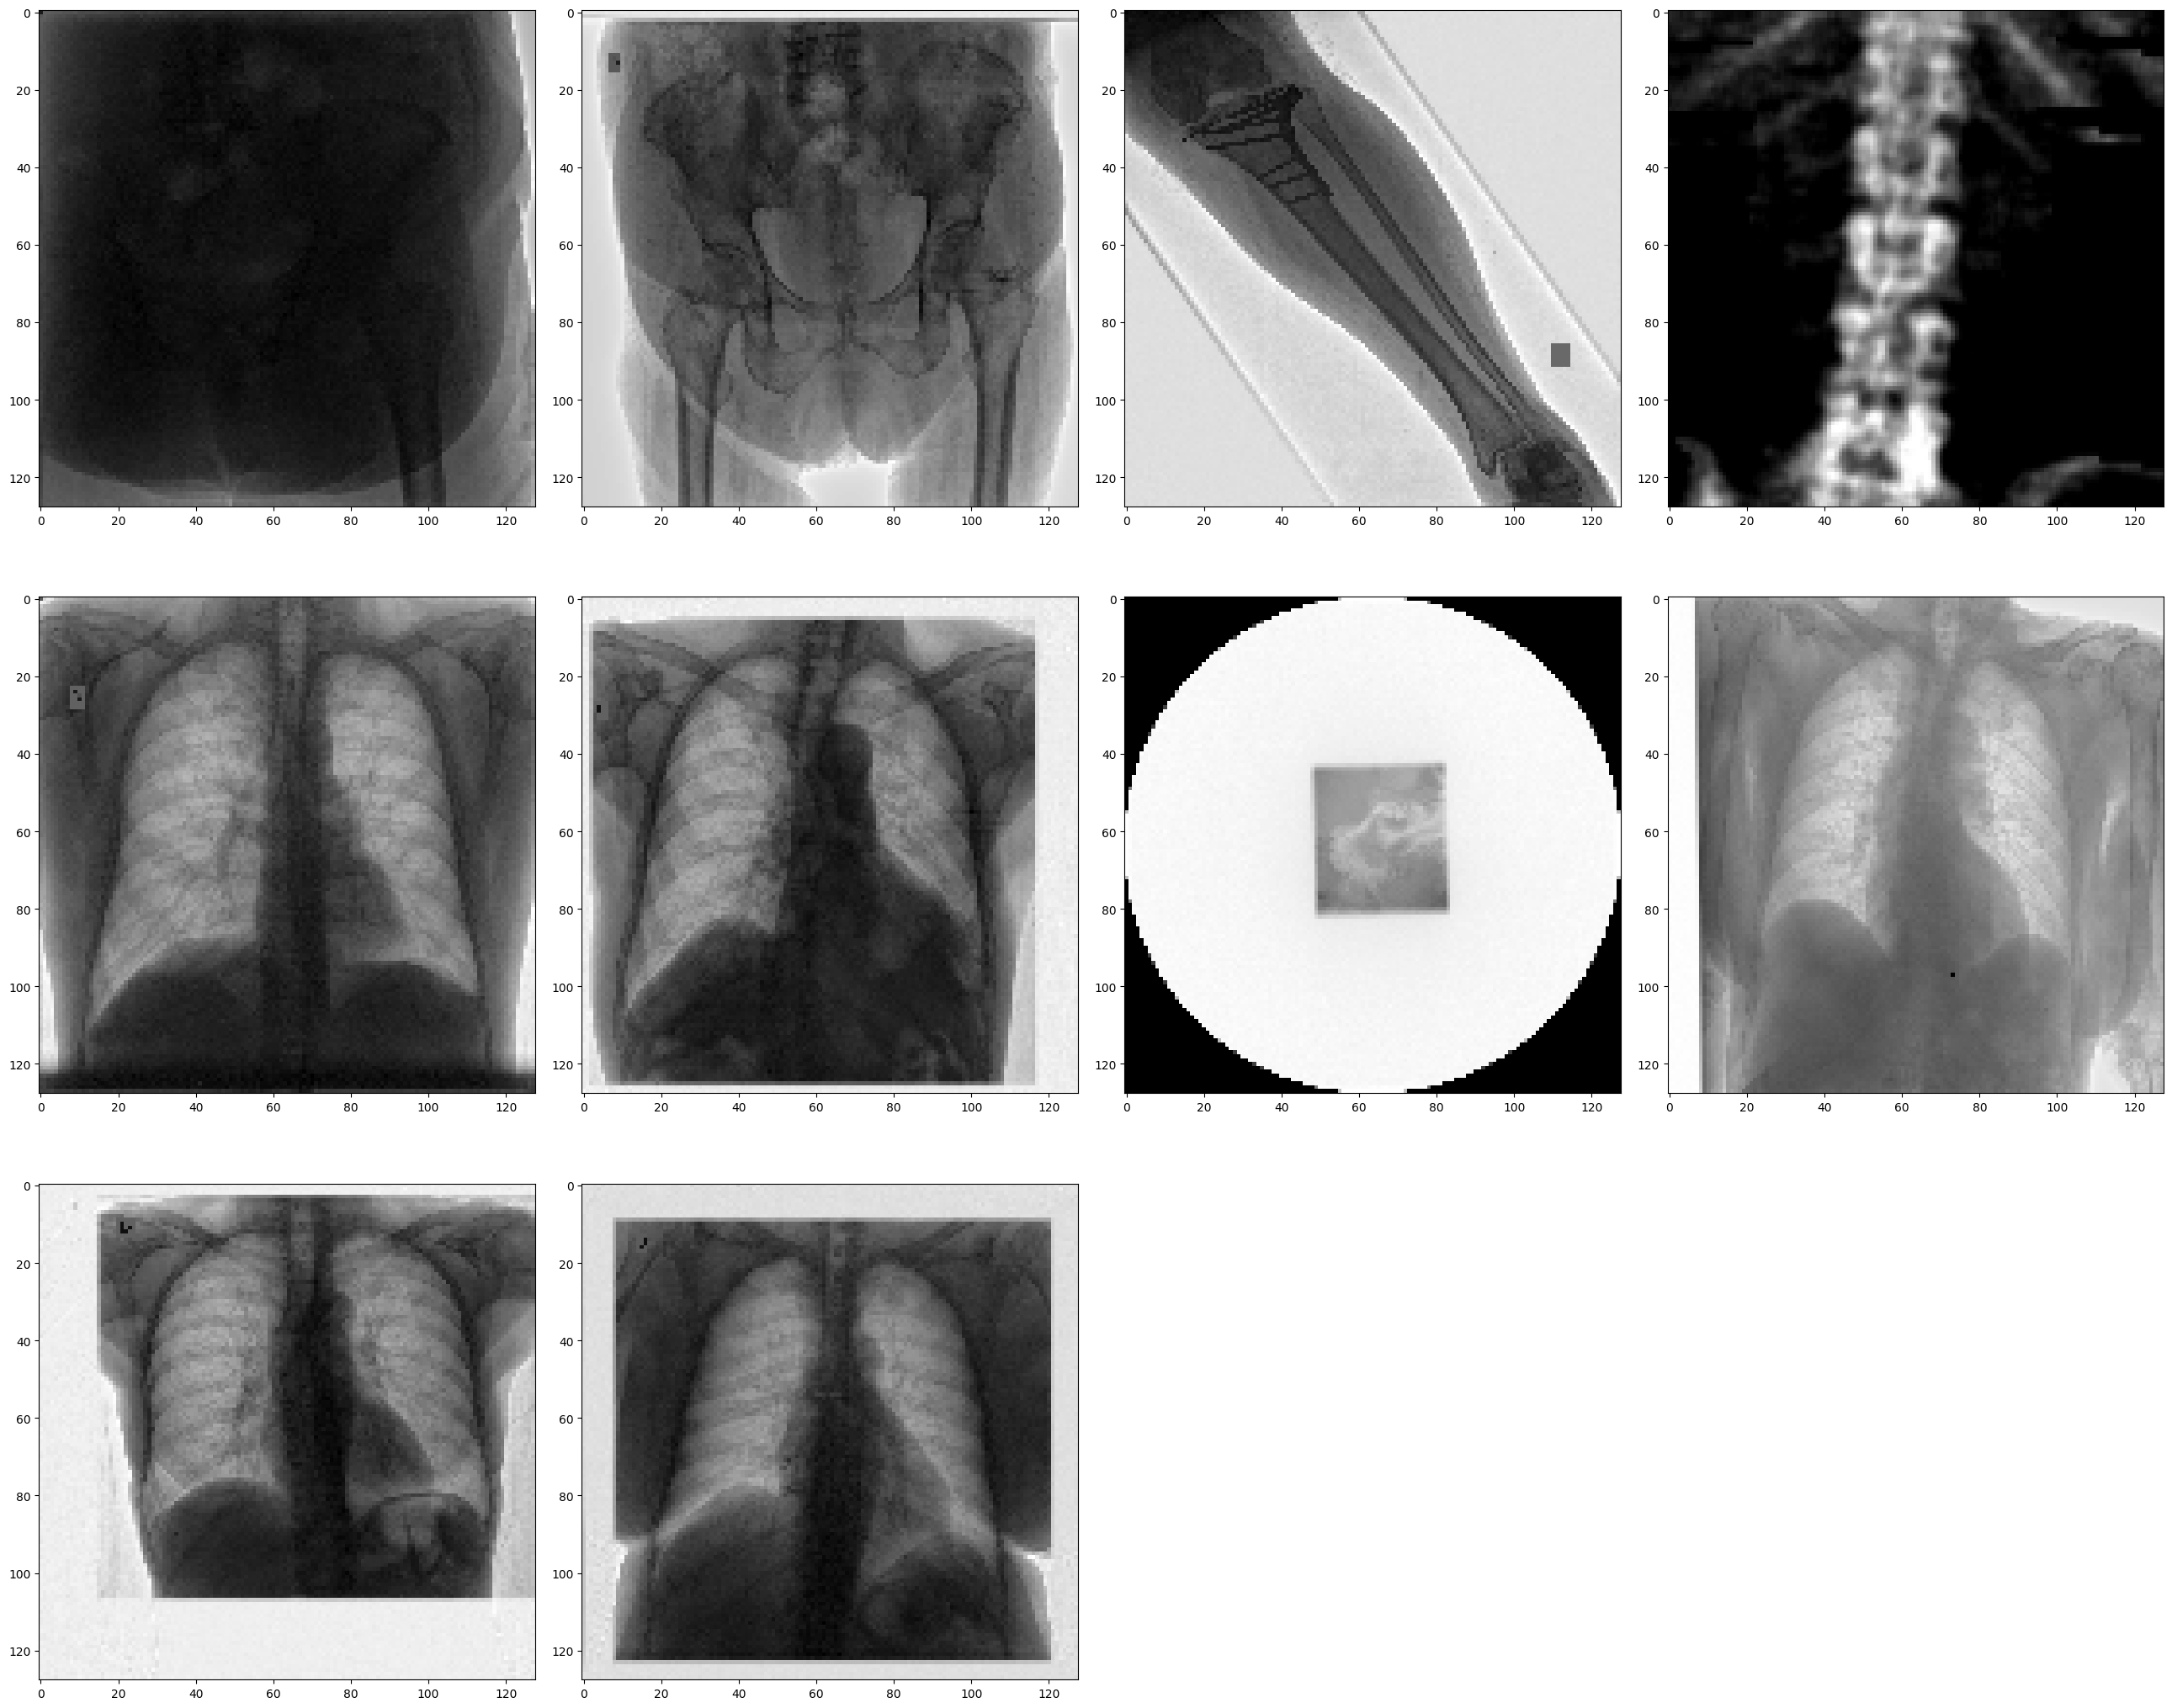

In [69]:
fig = plt.figure(figsize=(26,28))
for i in range(10):
    plt.subplot(4,4,i+1)
    plt.imshow(X[i],cmap='gray')
plt.tight_layout(pad=1.4)

[[[0.9249617 ]
  [0.91360295]
  [0.89847577]
  ...
  [0.9154029 ]
  [0.9197993 ]
  [0.9216988 ]]

 [[0.91259193]
  [0.9241421 ]
  [0.9254902 ]
  ...
  [0.91249233]
  [0.9228707 ]
  [0.9210861 ]]

 [[0.91588545]
  [0.9175169 ]
  [0.90647215]
  ...
  [0.9247779 ]
  [0.9111903 ]
  [0.9273284 ]]

 ...

 [[0.9298483 ]
  [0.9057521 ]
  [0.9154948 ]
  ...
  [0.92546725]
  [0.90882355]
  [0.92512256]]

 [[0.93149513]
  [0.91041666]
  [0.92443323]
  ...
  [0.8932215 ]
  [0.89654565]
  [0.9177619 ]]

 [[0.92156863]
  [0.91165745]
  [0.92840075]
  ...
  [0.9317938 ]
  [0.9332031 ]
  [0.9185049 ]]]


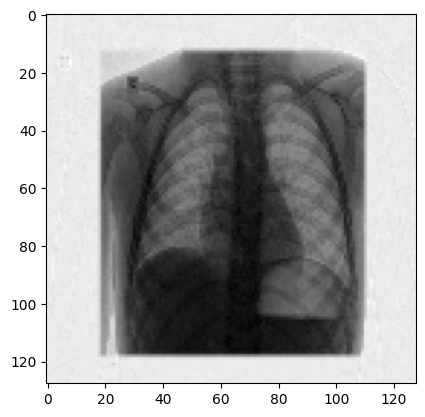

In [70]:
print(X[40])
plt.imshow(X[40],cmap='gray')

In [71]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.25)

In [79]:
model = tf.keras.models.Sequential()
model.add(Conv2D(64, kernel_size=(3,3), activation='relu', kernel_initializer='he_normal', padding='same', input_shape=(128,128,1)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, kernel_size=(3,3), activation='relu', kernel_initializer='he_normal', padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(256, kernel_size=(3,3), activation='relu', kernel_initializer='he_normal', padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(512, kernel_size=(3,3), activation='relu', kernel_initializer='he_normal', padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Dropout(0.6))

model.add(Flatten())
model.add(Dense(4096, activation="relu"))
model.add(Dense(2048, activation="relu"))
model.add(Dense(41, activation="softmax"))

model.compile(optimizer='Adam', loss='BinaryCrossentropy', metrics=['accuracy'])
model.summary()



C:\Users\ziqia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │   134,221,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2048)           │     8,390,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 41)             │        84,009 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 144,246,313 (550.26 MB)

 Trainable params: 144,246,313 (550.26 MB)

 Non-trainable params: 0 (0.00 B)

In [82]:
model.fit(x_train,y_train,batch_size=5,callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5)],epochs=25)

Epoch 1/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 94s 352ms/step - accuracy: 0.3911 - loss: 0.1876
Epoch 2/25


C:\Users\ziqia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\callbacks\early_stopping.py:153: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)


261/261 ━━━━━━━━━━━━━━━━━━━━ 91s 347ms/step - accuracy: 0.4457 - loss: 0.0733
Epoch 3/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 92s 351ms/step - accuracy: 0.5040 - loss: 0.0633
Epoch 4/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 93s 355ms/step - accuracy: 0.5813 - loss: 0.0545
Epoch 5/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 92s 353ms/step - accuracy: 0.6298 - loss: 0.0473
Epoch 6/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 92s 352ms/step - accuracy: 0.7110 - loss: 0.0371
Epoch 7/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 93s 358ms/step - accuracy: 0.7827 - loss: 0.0309
Epoch 8/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 91s 350ms/step - accuracy: 0.7885 - loss: 0.0267
Epoch 9/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 94s 360ms/step - accuracy: 0.8245 - loss: 0.0224
Epoch 10/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 94s 360ms/step - accuracy: 0.8673 - loss: 0.0173
Epoch 11/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 92s 351ms/step - accuracy: 0.8883 - loss: 0.0151
Epoch 12/25
261/261 ━━━━━━━━━━━━━━━━━━━━ 91s 350ms/step - accuracy: 0.9244 - loss: 0.0120
Epoch 13/25
261/261 ━━━━━━━━━

In [83]:
model.evaluate(x_test,y_test)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.7713 - loss: 0.0863


[0.0958477333188057, 0.7609195113182068]

In [85]:
model.save("xray_classifier.keras")